In [1]:
import csv
import json
import os
from pathlib import Path
import platform
import random
import re
from time import perf_counter
from urllib.request import urlretrieve

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from qa_model import (
    BACKBONE, Example, QAModel, Span, answer_scores, evaluate, load_tokenizer,
    make_features, make_loader, normalize, score_predictions, span_loss,
)

SEED = 42
LENGTHS = (128, 256, 384)
STRIDE = 64  # Fixed across all lengths, including the shortest setting.
BATCH_SIZE = 24
EPOCHS = 3
LEARNING_RATE = 3e-4
N_TRAIN, N_VALIDATION, N_TEST = 4096, 512, 768
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(6, os.cpu_count() or 1))
LAB = Path.cwd()
REPO = LAB
DATA = REPO / "datasets" / "squad-v1"
CHECKPOINT = REPO / "training_output" / "lab10" / "qa.pt"
DATA.mkdir(parents=True, exist_ok=True)
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
TOKENIZER = load_tokenizer()
print({"backbone": BACKBONE, "tokenizer": type(TOKENIZER).__name__, "dataset": "SQuAD 1.1",
       "epochs": EPOCHS, "seed": SEED, "lengths": LENGTHS, "stride": STRIDE,
       "batch_size": BATCH_SIZE, "optimizer": "AdamW", "lr": LEARNING_RATE,
       "device": str(DEVICE), "hardware": torch.cuda.get_device_name() if DEVICE.type == "cuda"
       else platform.processor(), "torch": str(torch.__version__)})

C:\Users\truon\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'backbone': 'google/bert_uncased_L-2_H-128_A-2', 'tokenizer': 'BertTokenizerFast', 'dataset': 'SQuAD 1.1', 'epochs': 3, 'seed': 42, 'lengths': (128, 256, 384), 'stride': 64, 'batch_size': 24, 'optimizer': 'AdamW', 'lr': 0.0003, 'device': 'cpu', 'hardware': 'Intel64 Family 6 Model 183 Stepping 1, GenuineIntel', 'torch': '2.14.1+cpu'}


In [2]:
def read_articles(split):
    name = f"{split}-v1.1.json"
    path = DATA / name
    if not path.exists():
        temporary = path.with_suffix(".part")
        urlretrieve(f"https://rajpurkar.github.io/SQuAD-explorer/dataset/{name}", temporary)
        temporary.replace(path)
    return json.loads(path.read_text(encoding="utf-8"))["data"]


def sample_examples(articles, limit, seed):
    examples = [
        Example(qa["id"], qa["question"], paragraph["context"],
                tuple((answer["text"], answer["answer_start"]) for answer in qa["answers"]))
        for article in articles
        for paragraph in article["paragraphs"]
        for qa in paragraph["qas"]
    ]
    return random.Random(seed).sample(examples, min(limit, len(examples)))


train_articles = read_articles("train")
dev_articles = read_articles("dev")
random.Random(SEED).shuffle(dev_articles)
cut = len(dev_articles) // 2
validation_articles, test_articles = dev_articles[:cut], dev_articles[cut:]
title_sets = [{article["title"] for article in group}
              for group in (train_articles, validation_articles, test_articles)]
assert all(not (titles & other) for index, titles in enumerate(title_sets) for other in title_sets[index+1:])
train = sample_examples(train_articles, N_TRAIN, SEED)
validation = sample_examples(validation_articles, N_VALIDATION, SEED + 1)
test = sample_examples(test_articles, N_TEST, SEED + 2)
print([(name, len(examples), len(titles)) for name, examples, titles
       in zip(("train", "validation", "test"), (train, validation, test), title_sets)])

[('train', 4096, 442), ('validation', 512, 24), ('test', 768, 24)]


In [3]:
def fit(max_length):
    torch.manual_seed(SEED)
    train_features, validation_features, test_features = [
        make_features(examples, TOKENIZER, max_length, STRIDE)
        for examples in (train, validation, test)
    ]
    training = make_loader(train_features, TOKENIZER, BATCH_SIZE, shuffle=True, seed=SEED)
    validating = make_loader(validation_features, TOKENIZER, BATCH_SIZE)
    testing = make_loader(test_features, TOKENIZER, BATCH_SIZE)
    model = QAModel(BACKBONE).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    history = []
    best_key = (-1.0, -1.0)
    train_seconds = 0.0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total = 0.0
        started = perf_counter()
        for inputs, (starts, ends), features in training:
            inputs = inputs.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            start, end = model(**inputs)
            loss = span_loss(start, end, starts.to(DEVICE), ends.to(DEVICE), inputs["attention_mask"])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(features)
        train_seconds += perf_counter() - started
        validation_loss, spans = evaluate(model, validating, len(validation), DEVICE)
        em, f1 = 100 * score_predictions(validation, spans).mean(axis=0)
        row = dict(epoch=epoch, train_loss=total / len(train_features), validation_loss=validation_loss,
                   em=em, f1=f1, training_seconds=train_seconds)
        history.append(row)
        print(f"length={max_length} epoch={epoch} train_loss={row['train_loss']:.4f} "
              f"val_loss={validation_loss:.4f} EM={em:.2f} F1={f1:.2f}", flush=True)
        if (f1, em) > best_key:
            best_key = (f1, em)
            best_epoch = epoch
            weights = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}

    model.load_state_dict(weights)
    test_loss, spans = evaluate(model, testing, len(test), DEVICE)
    return dict(max_length=max_length, history=history, best_epoch=best_epoch, key=best_key,
                train_windows=len(train_features), test_windows=len(test_features),
                weights=weights, test_loss=test_loss, predictions=spans)


runs = [fit(length) for length in LENGTHS]
selected = max(runs, key=lambda run: (*run["key"], -run["max_length"]))
torch.save(dict(backbone=BACKBONE, max_length=selected["max_length"], stride=STRIDE,
                state_dict=selected["weights"]), CHECKPOINT)
print(f"Selected length={selected['max_length']}, epoch={selected['best_epoch']}; checkpoint={CHECKPOINT}")

You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


length=128 epoch=1 train_loss=2.7897 val_loss=2.7234 EM=7.23 F1=13.91


length=128 epoch=2 train_loss=2.0827 val_loss=2.6628 EM=9.77 F1=21.51


length=128 epoch=3 train_loss=1.5360 val_loss=2.9547 EM=9.77 F1=21.74


length=256 epoch=1 train_loss=3.9195 val_loss=3.3109 EM=14.84 F1=24.47


length=256 epoch=2 train_loss=3.0671 val_loss=3.0978 EM=18.55 F1=30.86


length=256 epoch=3 train_loss=2.3738 val_loss=3.2600 EM=18.36 F1=30.10


length=384 epoch=1 train_loss=3.9993 val_loss=3.3814 EM=14.65 F1=26.34


length=384 epoch=2 train_loss=3.1480 val_loss=3.1840 EM=18.16 F1=29.79


length=384 epoch=3 train_loss=2.4018 val_loss=3.2789 EM=18.75 F1=29.53


Selected length=256, epoch=2; checkpoint=E:\Hus\NLP\training_output\lab10\qa.pt


In [4]:
STOP = set("what which where when who why how is was are were be did does do has have had "
           "of in at to for from by and or with on as it its this that".split())


def words(text):
    return set(re.findall(r"[a-z0-9]+", normalize(text))) - STOP


def baseline(example):
    question_words = words(example.question)
    lead = example.question.lower().split()[:2]
    numeric = lead[:1] == ["when"] or lead == ["how", "many"] or lead == ["how", "much"]
    entity = bool(lead and lead[0] in {"who", "where"})
    sentences = list(re.finditer(r"[^.!?]+(?:[.!?]+|$)", example.context))
    if not sentences:
        return Span()
    sentence = max(sentences, key=lambda match: len(words(match.group()) & question_words))
    tokens = list(re.finditer(r"[A-Za-z0-9]+(?:[-'][A-Za-z0-9]+)*", sentence.group()))
    anchors = [index for index, token in enumerate(tokens) if token.group().lower() in question_words]
    best = Span()
    for first, token in enumerate(tokens):
        for last in range(first, min(first + 5, len(tokens))):
            phrase = tokens[first:last + 1]
            forms = [item.group() for item in phrase]
            novel = sum(form.lower() not in question_words | STOP for form in forms)
            if not novel or forms[0].lower() in STOP or forms[-1].lower() in STOP:
                continue
            has_number = any(any(char.isdigit() for char in form) for form in forms)
            capitals = sum(form[0].isupper() and (first + index > 0) for index, form in enumerate(forms))
            distance = min((min(abs(first - a), abs(last - a)) for a in anchors), default=10)
            score = (3 * has_number if numeric else 0) + (1.0 if entity else .3) * capitals
            score += .3 * novel - .55 * (last - first) - .12 * distance
            if score > best.score:
                best = Span(sentence.start() + token.start(), sentence.start() + tokens[last].end(), score)
    return best


models = {
    "Keyword baseline": [baseline(example) for example in test],
    "Fine-tuned BERT-Tiny": selected["predictions"],
}
scores = {model: 100 * score_predictions(test, spans) for model, spans in models.items()}
overlap = np.array([len(words(ex.question) & words(ex.context)) / max(1, len(words(ex.question))) for ex in test])
threshold = float(np.median(overlap))
groups = {"Lower overlap": overlap < threshold, "Higher overlap": overlap >= threshold}
if not all(mask.any() for mask in groups.values()):
    groups = {"Lower overlap": overlap <= threshold, "Higher overlap": overlap > threshold}
gold_lengths = np.array([len(ids) for ids in TOKENIZER(
    [ex.answers[0][0] for ex in test], add_special_tokens=False)["input_ids"]])
buckets = {"1": gold_lengths == 1, "2–3": (gold_lengths >= 2) & (gold_lengths <= 3),
           "4–6": (gold_lengths >= 4) & (gold_lengths <= 6), "7+": gold_lengths >= 7}

rows = []
for run in runs:
    length = run["max_length"]
    for row in run["history"]:
        rows.append(dict(experiment="learning_curve", split="validation", model="Fine-tuned BERT-Tiny",
                         max_length=length, stride=STRIDE, n_examples=len(validation),
                         n_windows=run["train_windows"], group="all", **row))
    em, f1 = 100 * score_predictions(test, run["predictions"]).mean(axis=0)
    rows.append(dict(experiment="context_length", split="test", model="Fine-tuned BERT-Tiny",
                     max_length=length, stride=STRIDE, epoch=run["best_epoch"], group="all",
                     n_examples=len(test), n_windows=run["test_windows"], em=em, f1=f1,
                     test_loss=run["test_loss"], training_seconds=run["history"][-1]["training_seconds"]))
for experiment, masks in (("em_vs_f1", {"all": np.ones(len(test), dtype=bool)}),
                          ("question_context_matching", groups), ("answer_length", buckets)):
    for group, mask in masks.items():
        for model, matrix in scores.items():
            em, f1 = matrix[mask].mean(axis=0) if mask.any() else (None, None)
            is_bert = model == "Fine-tuned BERT-Tiny"
            rows.append(dict(experiment=experiment, split="test", model=model,
                             max_length=selected["max_length"] if is_bert else None,
                             stride=STRIDE if is_bert else None,
                             epoch=selected["best_epoch"] if is_bert else None,
                             group=group, n_examples=int(mask.sum()), em=em, f1=f1))
columns = list(dict.fromkeys(key for row in rows for key in row))
with (LAB / "results.csv").open("w", encoding="utf-8-sig", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(rows)
table = pd.DataFrame(rows)
print(f"Lexical overlap median: {threshold:.3f}")
display(table[table.experiment != "learning_curve"][
    ["experiment", "model", "max_length", "group", "n_examples", "em", "f1", "training_seconds"]
].round(2))

Lexical overlap median: 0.667


,experiment,model,max_length,group,n_examples,em,f1,training_seconds
3,context_length,Fine-tuned BERT-Tiny,128.0,all,768,10.55,22.97,137.16
7,context_length,Fine-tuned BERT-Tiny,256.0,all,768,23.18,32.76,141.90
11,context_length,Fine-tuned BERT-Tiny,384.0,all,768,21.88,32.65,180.39
12,em_vs_f1,Keyword baseline,NaN,all,768,16.15,23.85,NaN
13,em_vs_f1,Fine-tuned BERT-Tiny,256.0,all,768,23.18,32.76,NaN
14,question_context_matching,Keyword baseline,NaN,Lower overlap,308,13.64,18.66,NaN
15,question_context_matching,Fine-tuned BERT-Tiny,256.0,Lower overlap,308,20.78,29.60,NaN
16,question_context_matching,Keyword baseline,NaN,Higher overlap,460,17.83,27.33,NaN
17,question_context_matching,Fine-tuned BERT-Tiny,256.0,Higher overlap,460,24.78,34.87,NaN
18,answer_length,Keyword baseline,NaN,1,156,20.51,21.69,NaN


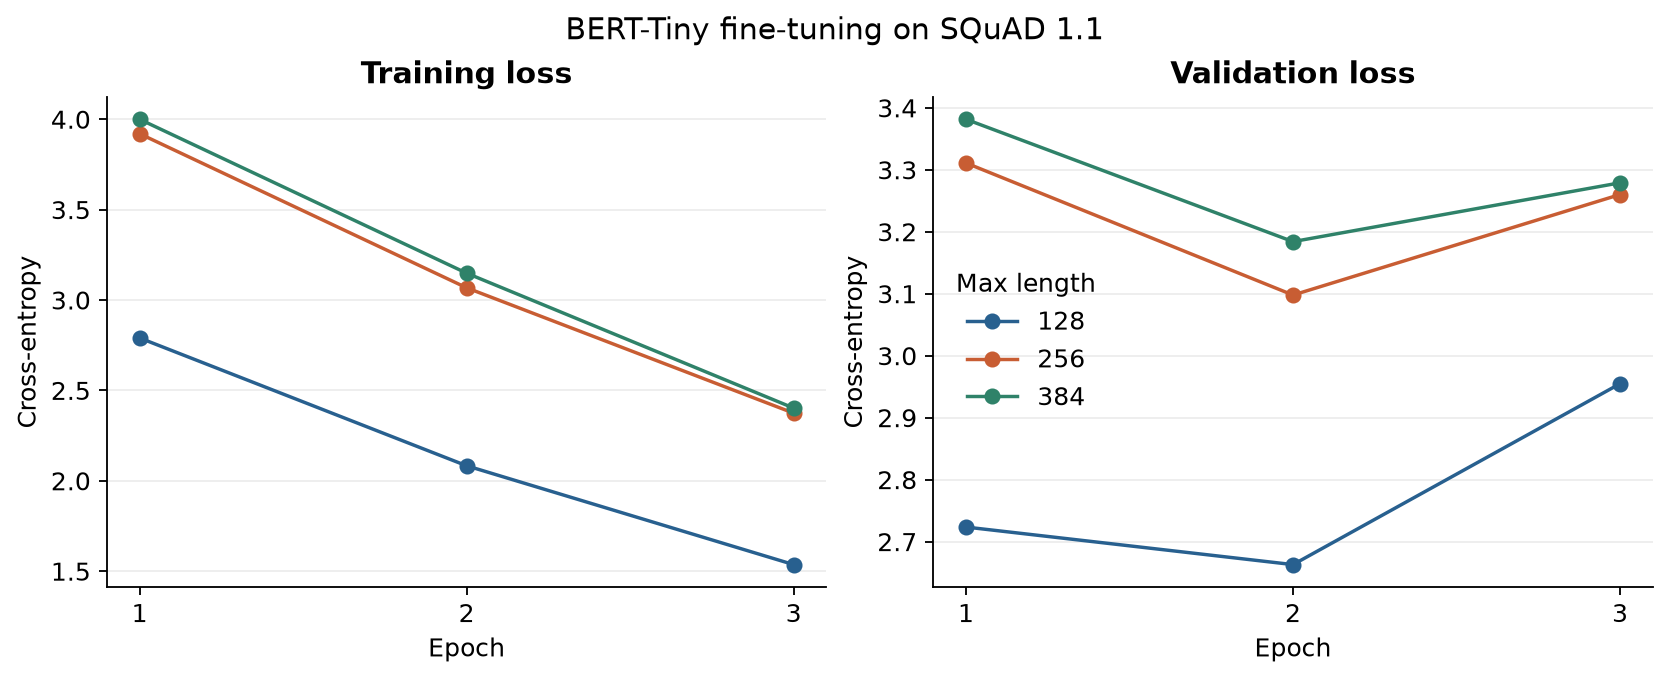

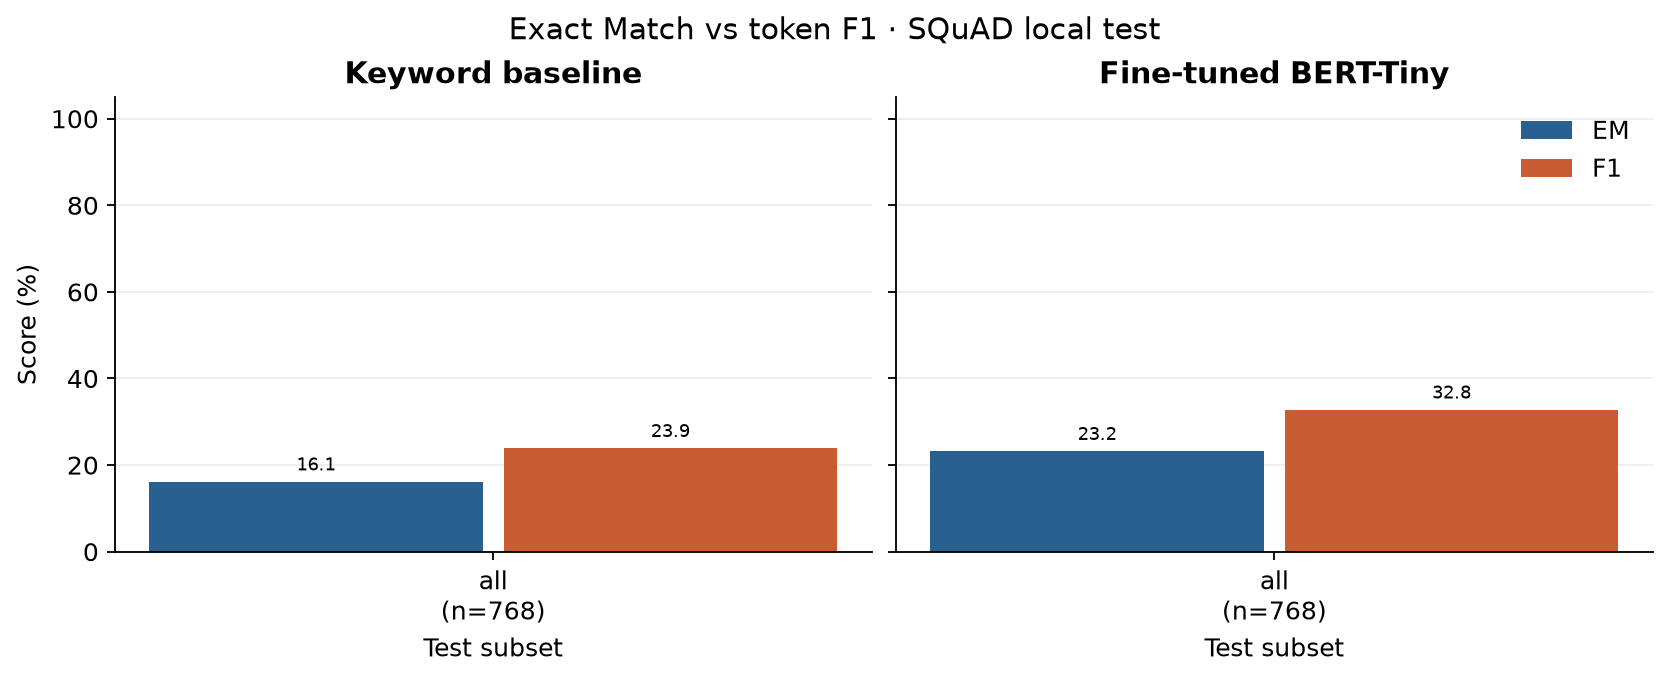

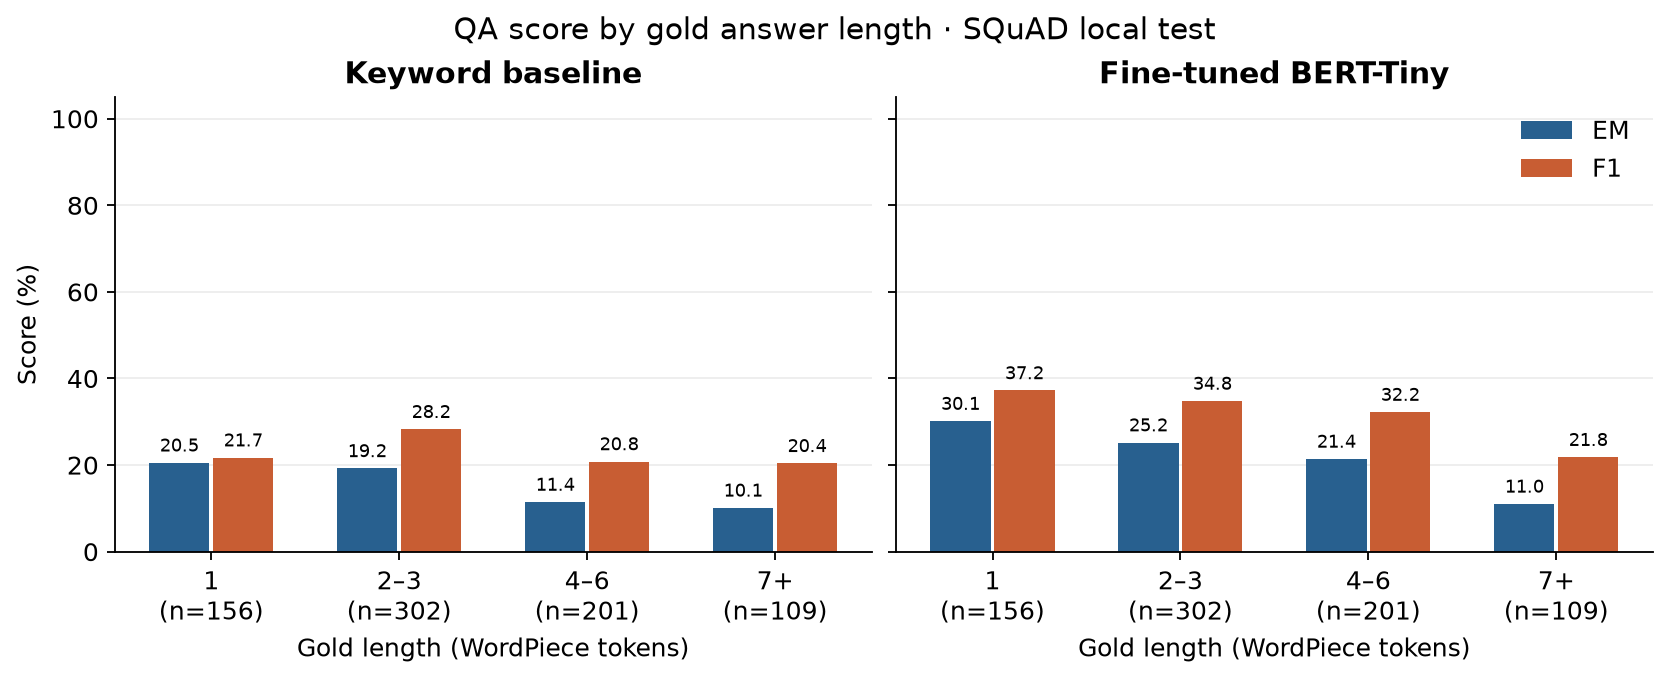

In [5]:
plt.rcParams.update({"figure.dpi": 130, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
blue, orange = "#28608F", "#C85D33"


def save_chart(fig, name):
    fig.savefig(LAB / name, dpi=165, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(LAB / name)))


fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for run, color in zip(runs, (blue, orange, "#2F8269")):
    history = run["history"]
    epochs = [row["epoch"] for row in history]
    length = run["max_length"]
    for ax, key, title in zip(axes, ("train_loss", "validation_loss"), ("Training loss", "Validation loss")):
        ax.plot(epochs, [row[key] for row in history], marker="o", color=color, label=str(length))
        ax.set(title=title, xlabel="Epoch", ylabel="Cross-entropy", xticks=epochs)
        ax.grid(axis="y", alpha=.23)
axes[1].legend(title="Max length", frameon=False)
fig.suptitle("BERT-Tiny fine-tuning on SQuAD 1.1")
save_chart(fig, "learning_curves.png")


def metric_chart(experiment, labels, title, filename, xlabel):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout="constrained")
    data = table[table.experiment == experiment]
    x = np.arange(len(labels))
    for ax, (model, _) in zip(axes, models.items()):
        subset = data[data.model == model].set_index("group").reindex(labels)
        for metric, shift, color in (("em", -.17, blue), ("f1", .17, orange)):
            bars = ax.bar(x + shift, subset[metric], .32, color=color, label=metric.upper())
            ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=3)
        ax.set(title=model, xlabel=xlabel, xticks=x, ylim=(0, 105))
        ax.set_xticklabels([f"{label}\n(n={int(count)})" for label, count in zip(labels, subset.n_examples)])
        ax.grid(axis="y", alpha=.23)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("Score (%)")
    axes[1].legend(frameon=False, loc="upper right")
    fig.suptitle(title)
    save_chart(fig, filename)


metric_chart("em_vs_f1", ["all"], "Exact Match vs token F1 · SQuAD local test",
             "em_f1_analysis.png", "Test subset")
metric_chart("answer_length", list(buckets), "QA score by gold answer length · SQuAD local test",
             "answer_length_analysis.png", "Gold length (WordPiece tokens)")

In [6]:
model_name = "Fine-tuned BERT-Tiny"
error_rows = []
for example, span, (em, f1) in zip(test, models[model_name], scores[model_name]):
    prediction = span.text(example.context)
    gold, start = max(example.answers, key=lambda ans: (
        answer_scores(prediction, ans[0])[1],
        -abs(span.start - ans[1]) - abs(span.end - (ans[1] + len(ans[0])))))
    end = start + len(gold)
    wrong_start, wrong_end = span.start != start, span.end != end
    if not (wrong_start or wrong_end):
        continue
    kind = "Wrong span" if wrong_start and wrong_end else ("Wrong start" if wrong_start else "Wrong end")
    if max(span.start, start) >= min(span.end, end):
        detail = "Disjoint character intervals; inspect the chosen sentence and competing spans."
    elif span.start >= start and span.end <= end:
        detail = "Prediction omits part of the gold span."
    elif span.start <= start and span.end >= end:
        detail = "Prediction includes the gold span plus surrounding text."
    else:
        detail = "Prediction and gold overlap, but one side shifts beyond the reference."
    error_rows.append(dict(question=example.question, gold=gold, prediction=prediction,
                           error=kind, explanation=detail, em=em, f1=f1,
                           wrong_start=wrong_start, wrong_end=wrong_end))
errors = pd.DataFrame(error_rows)
print(f"Wrong starts: {errors.wrong_start.sum()}; wrong ends: {errors.wrong_end.sum()}")
for category in ("Wrong start", "Wrong end", "Wrong span"):
    display(errors[errors.error == category].head(5)[["question", "gold", "prediction", "error", "explanation"]])
partial = errors[(errors.em == 0) & (errors.f1 > 0)]
display(partial.head(5)[["question", "gold", "prediction", "em", "f1", "explanation"]])

Wrong starts: 537; wrong ends: 533


,question,gold,prediction,error,explanation
20,Why aren't the examples of bouregois architect...,not restored by the communist authorities afte...,bourgeois architecture of the later periods we...,Wrong start,Prediction includes the gold span plus surroun...
24,What does the beroida have instead of feeding ...,large pharynx,"no feeding appendages, but their large pharynx",Wrong start,Prediction includes the gold span plus surroun...
27,What rank for most populous city in the Europe...,9th,Warsaw the 9th,Wrong start,Prediction includes the gold span plus surroun...
32,Where is the Apostles located?,Small Catechism,the Apostles' Creed in the Small Catechism,Wrong start,Prediction includes the gold span plus surroun...
36,What set is a seat added to after being alloca...,second,allocating the second,Wrong start,Prediction includes the gold span plus surroun...


,question,gold,prediction,error,explanation
11,What was the name of the fund setup to help wi...,50 fund,50,Wrong end,Prediction omits part of the gold span.
29,Ludwig Krapf recorded the name was what?,Kenia and Kegnia,Kenia,Wrong end,Prediction omits part of the gold span.
50,What is the name of Newcastle's first full-tim...,NE1fm,NE1fm launched on 8 June 2007,Wrong end,Prediction includes the gold span plus surroun...
52,What was the name of the work to give grants f...,50 fund,50 fund as its philanthropic initiative and fo...,Wrong end,Prediction includes the gold span plus surroun...
53,What river was there originally a bridge acros...,the River Tyne,the River,Wrong end,Prediction omits part of the gold span.


,question,gold,prediction,error,explanation
0,Who will be the new executive producer of Doct...,Chris Chibnall,"January 2016, Moffat",Wrong span,Disjoint character intervals; inspect the chos...
1,How high in altitude in feet could the vacuum ...,"250,000",Apollo spacecraft,Wrong span,Disjoint character intervals; inspect the chos...
2,How much of the population of Earth ended up s...,one-quarter,Apollo 8,Wrong span,Disjoint character intervals; inspect the chos...
3,"Prior to Super Bowl 50, when were the Broncos ...",Super Bowl XLVIII,John Fox,Wrong span,Disjoint character intervals; inspect the chos...
4,What song did Coldplay and Beyoncé collaborate...,"""Hymn for the Weekend""","British rock group Coldplay. On January 7, 2016",Wrong span,Disjoint character intervals; inspect the chos...


,question,gold,prediction,em,f1,explanation
10,Why might rats not be responsible for the plague?,rat population was insufficient to account for...,modern bubonic,0.0,16.666667,Disjoint character intervals; inspect the chos...
11,What was the name of the fund setup to help wi...,50 fund,50,0.0,66.666667,Prediction omits part of the gold span.
16,What is grown in the fertile highlands?,"ea, coffee, sisal, pyrethrum, corn, and wheat",corn,0.0,25.000000,Disjoint character intervals; inspect the chos...
20,Why aren't the examples of bouregois architect...,not restored by the communist authorities afte...,bourgeois architecture of the later periods we...,0.0,70.000000,Prediction includes the gold span plus surroun...
23,What is the metric term less used than the New...,pound-force,The pound-force has a metric counterpart,0.0,40.000000,Prediction includes the gold span plus surroun...
